# 20 — Sintéticos IV: aumento de datos (real + sintético)

¿Entrenar los detectores del benchmark con **real + sintético** mejora su detección de las crisis
**reales** fuera de muestra? Se evalúa solo sobre el real OOS, con el mismo `walk_forward`, las mismas
specs y las mismas métricas ADR-003 que el benchmark; la referencia (proporción 0) son sus paneles
OOS, así que la comparación es pareada día a día. Todo el diseño está pre-registrado (2026-10-15,
antes de ejecutar nada) en [`configs/sinteticos.yaml → aumento`](../../configs/sinteticos.yaml), con sus
concreciones y erratas fechadas. Ninguna cifra de resultados está escrita a mano (salvo las conclusiones, que resumen las
salidas): salen de las celdas.

## 0. Por qué este alcance

- **Generadores: los `apto_aumento` del 18 en las dos pistas** — `gaussiano_regimen`, `var_regimen`,
  `garch_regimen`, `rbig` y `flow_matching`. El criterio lo fijó el 18, no este notebook, y es el mismo
  conjunto en A y B para que las pistas sean comparables. `bootstrap_regimen` (días reales remuestreados)
  no es apto porque memoriza: entra **solo como control** («¿basta con cualquier dato extra?»).
- **Por qué no el alcance completo.** `difusion`, `cvae` y `cgan` son aptos solo en A (en B no pasan el
  condicionamiento): romperían la comparabilidad entre pistas y añadirían unas 19 h de cálculo. Quedan
  como extensión posible, declarada como tal.
- **Detectores: todos los evaluables** (12 en A; 10 en B, donde D02 y D10 usan columnas que los
  generadores no producen). Se descartó recortar A al top-8 del ranking porque dejaba fuera justo a los
  que aprenden un estado de crisis (D04, D08, D09, D11), los que más podrían beneficiarse: el recorte
  sesgaba en contra de encontrar efecto. Un resultado nulo solo es creíble si es amplio.
- **Expectativa declarada: efecto pequeño o nulo.** Los detectores son no supervisados (el aumento solo
  cambia la ley que ven al ajustarse); en el TSTR del 18, entrenar solo con sintético quedó casi siempre
  por debajo del real; y en las reglas de umbral el aumento recalibra umbrales en vez de aprender.
- **Coste.** Unas 400–460 h de CPU, ejecutadas por sesiones de 8 h con 10 procesos
  (`python -m regimenes.sinteticos.aumento ejecutar`, reanudable; hechas en 12 sesiones, 1.166 trabajos) y por lotes de prioridad, cada uno con
  resultados completos. Este notebook **solo lee** los CSV consolidados
  (`python -m regimenes.sinteticos.aumento consolidar`) y funciona con resultados parciales: lo que
  falta sale como «falta», nunca como cero.

**Índice.** 1. Configuración y estado · 2. Diseño · 3. H1 (principal) · 4. Mapa detector × generador ·
5. H2 dosis-respuesta · 6. H3, H4 y H5 · 7. Diagnósticos · 8. Regla para el 21 y conclusiones

## 1. Configuración y estado de la ejecución

Pre-registro resumido y cobertura: trabajos hechos y pendientes por lote de prioridad (en el orden en
que se lanzan) y horas de CPU estimadas para lo que falta. La carpeta de resultados es la real salvo que
la variable de entorno `NB18_RESULTADOS` apunte a otra.

In [1]:
%matplotlib inline
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from regimenes import viz
from regimenes.sinteticos.aumento import analisis as an
from regimenes.sinteticos.aumento import figuras as fg
from regimenes.sinteticos.aumento.anclas import leer_registro, ruta_registro
from regimenes.sinteticos.aumento.config import DIR_RESULTADOS, config_aumento

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 110)
viz.use_house_style()

RES = Path(os.environ.get('NB18_RESULTADOS', DIR_RESULTADOS))   # carpeta de resultados (por defecto, la real)
FIGS = RES / 'figuras'
CFG = config_aumento()
PISTAS = CFG['pistas']


def guardar(obj, nombre):
    # tabla -> RES/<nombre>.csv (si no está vacía) ; figura -> FIGS/<nombre>.png (y se muestra)
    if isinstance(obj, pd.DataFrame):
        if not obj.empty:
            obj.to_csv(RES / f'{nombre}.csv', index=False)
        return
    FIGS.mkdir(parents=True, exist_ok=True)
    obj.savefig(FIGS / f'{nombre}.png', dpi=130, bbox_inches='tight')
    plt.show()


pre = {k: CFG[k] for k in ('generadores', 'control', 'excluir', 'proporciones', 'repeticiones', 'trayectoria_largo')}
pre.update({'margen_reconocimiento': CFG['anclas']['margen_reconocimiento'], 'h1': CFG['contrastes']['h1'],
            'mejora_minima': CFG['contrastes']['mejora_minima'], 'n_boot': CFG['contrastes']['n_boot']})
display(pd.Series({k: json.dumps(v, ensure_ascii=False) for k, v in pre.items()}, name='valor').to_frame())
COB = an.cobertura(PISTAS, RES)
display(COB.round(1))
DATOS = an.cargar(PISTAS, RES)
FILAS = an.cargar_filas(PISTAS, RES)
print(f'Trabajos hechos: {int(COB.hechos.sum())} de {int(COB.trabajos.sum())}; '
      f'pendientes ~{COB.horas_cpu_pendientes.sum():.0f} h de CPU. Pistas consolidadas: {list(DATOS) or "ninguna"}')
for p, d in DATOS.items():
    print(f'  {p}: señales por tipo {d.senales["tipo"].value_counts().to_dict()}; {len(d.nombres_segmento)} segmentos')

,valor
generadores,"[""gaussiano_regimen"", ""var_regimen"", ""garch_regimen"", ""rbig"", ""flow_matching""]"
control,"""bootstrap_regimen"""
excluir,"{""B"": [""D02"", ""D10""]}"
proporciones,"[0.25, 0.5, 1.0]"
repeticiones,"{""A"": 1, ""B"": 2}"
trayectoria_largo,2520
margen_reconocimiento,126
h1,"{""brazo"": ""completas"", ""proporcion"": 1.0, ""senal"": ""voto_mayoritario"", ""voto_min"": 3, ""correccion"": ""holm""}"
mejora_minima,0.03
n_boot,20000


,lote,pista,contenido,trabajos,hechos,pendientes,horas_cpu_pendientes
0,0,B,pista B | repeticion 0,370,370,0,0.0
1,1,A,"pista A | D01,D02,D03,D06,D07,D12",220,220,0,0.0
2,2,A,"pista A | D10,D11",72,72,0,0.0
3,3,A,pista A | D05,36,36,0,0.0
4,4,A,"pista A | D09,D08 | brazo completas",36,36,0,0.0
5,5,A,"pista A | D09,D08 | brazo crisis",36,36,0,0.0
6,6,A,pista A | D04,36,36,0,0.0
7,7,B,pista B | repeticion 1,360,360,0,0.0


Trabajos hechos: 1166 de 1166; pendientes ~0 h de CPU. Pistas consolidadas: ['A', 'B']
  A: señales por tipo {'fuente': 360, 'voto': 72, 'control': 72, 'base': 12, 'suelo': 4}; 17 segmentos
  B: señales por tipo {'fuente': 600, 'voto': 120, 'control': 120, 'base': 10, 'suelo': 10}; 9 segmentos


## 2. Diseño: un pliegue y el registro de anclas

Arriba, un pliegue real: el bloque sintético va **delante** del train real, con fechas hábiles ficticias,
y la cola del train (contexto al predecir) sigue siendo real. El generador de ese pliegue es el ajustado
en el **ancla** τ = última fin de año válida al menos `margen_reconocimiento` sesiones antes del fin del
train, con datos ≤ τ y etiquetas solo de crisis ya reconocidas (suelo ≤ τ). Las proporciones son
**anidadas**: el bloque de 0,25 son las primeras filas del reservorio que también abren los de 0,5 y 1.
El brazo *crisis* añade solo episodios de crisis, con `p ×` los días de crisis reconocidos del train.
Debajo, el registro de anclas: un ancla vale si su ajuste tiene crisis suficientes y el generador pasa en
ella la memorización y el condicionamiento del 18; si no, se usa la válida anterior, y sin ninguna el
pliegue va sin aumento (Δ = 0 en ese pliegue).

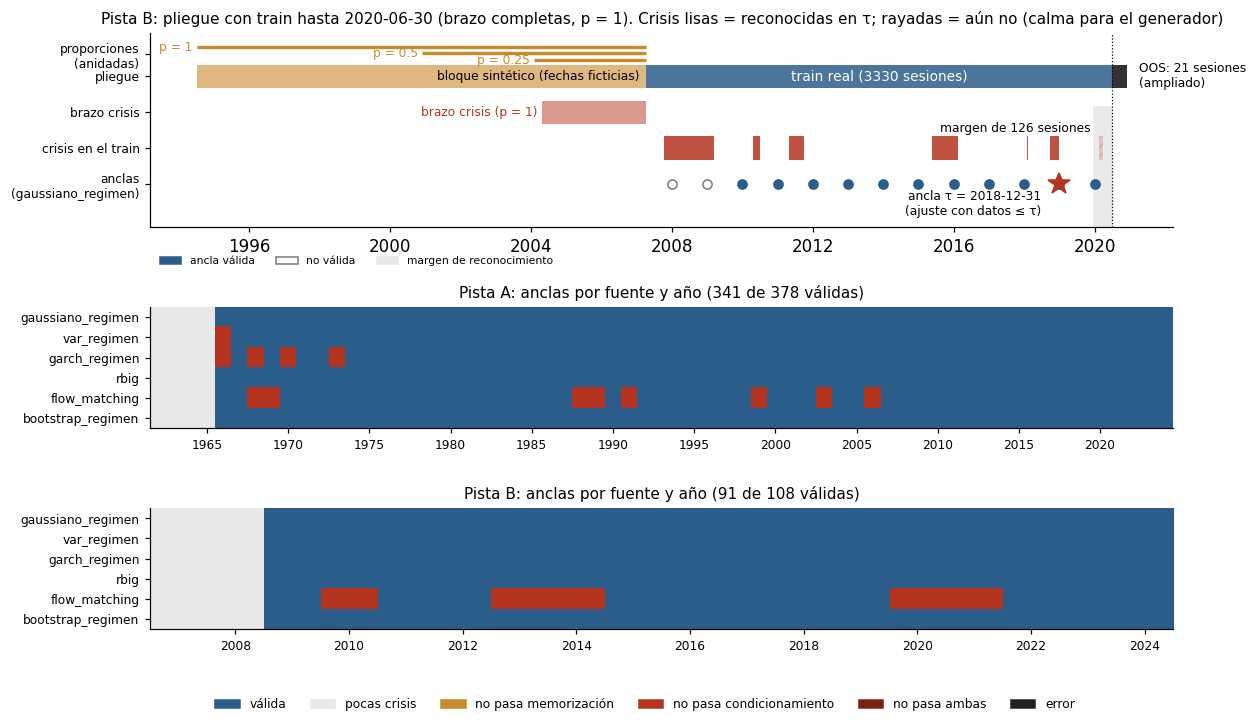

candidatas  valida  pocas crisis  no pasa memorizacion  no pasa condicionamiento  no pasa ambas  error primera_valida
pista fuente                                                                                                                                  
A     bootstrap_regimen          63      59             4                     0                         0              0      0     1966-12-30
      flow_matching              63      51             4                     0                         8              0      0     1966-12-30
      garch_regimen              63      55             4                     0                         4              0      0     1967-12-29
      gaussiano_regimen          63      59             4                     0                         0              0      0     1966-12-30
      rbig                       63      59             4                     0                         0              0      0     1966-12-30
      var_regimen                63      58             4                     0                         1              0      0     1967-12-29
B     bootstrap_regimen          18      16             2                     0                         0              0      0     2009-12-31
      flow_matching              18      11             2                     0                         5              0      0     2009-12-31
      garch_regimen              18      16             2                     0                         0              0      0     2009-12-31
      gaussiano_regimen          18      16             2                     0                         0              0      0     2009-12-31
      rbig                       18      16             2                     0                         0              0      0     2009-12-31
      var_regimen                18      16             2                     0                         0              0      0     2009-12-31

In [2]:
REGISTROS = {p: leer_registro(p, RES) for p in PISTAS if ruta_registro(p, RES).exists()}
guardar(fg.fig_diseno(REGISTROS, CFG), 'diseno')
display(an.resumen_anclas(REGISTROS))

## 3. Contraste principal (H1)

Por pista y detector: Δ del **exceso sobre el nulo** (score − mediana del nulo de azar persistente con la
tasa y la racha de la propia señal) entre la señal de **voto** (≥ 3 de 5 generadores; brazo completas,
p = 1, repetición 0) y el benchmark. p-valor por permutación pareada exacta de segmentos (uno por
crisis) con Holm por pista (12 contrastes en A y 10 en B; errata fechada antes de ver
resultados; el Holm global sobre los 22 se publica como sensibilidad); IC 95 % por bootstrap de segmentos. «Mejora» exige las cinco
condiciones (a) Holm y Δ > 0, (b) Δ ≥ `mejora_minima`, (c) el nivel ADR-003 no empeora, (d) ningún
generador con IC por debajo de 0 y (e) Δ por encima del suelo de ruido donde lo hay. Un contraste que
aún no está cuenta con p = 1 («falta») y no encoge la familia.

,pista,detector,veredicto,delta,ic_inf,ic_sup,p,holm,holm_global,veredicto_global,a_holm,b_minima,c_nivel,d_generadores,e_suelo,nivel_base,nivel_aumento,suelo_ruido
0,A,D01,sin efecto detectable,-0.012,-0.022,-0.002,0.061,False,False,sin efecto detectable,False,False,True,False,True,0,0,NaN
1,A,D02,sin efecto detectable,-0.014,-0.074,0.067,0.656,False,False,sin efecto detectable,False,False,True,True,True,0,0,NaN
2,A,D03,sin efecto detectable,0.021,-0.048,0.068,0.574,False,False,sin efecto detectable,False,False,True,True,True,0,0,0.005
3,A,D04,sin efecto detectable,0.088,0.024,0.131,0.032,False,False,sin efecto detectable,False,True,True,True,True,0,0,NaN
4,A,D05,sin efecto detectable,0.007,-0.006,0.021,0.263,False,False,sin efecto detectable,False,False,True,False,True,0,0,NaN
5,A,D06,sin efecto detectable,0.016,0.005,0.033,0.010,False,False,sin efecto detectable,False,False,True,False,True,0,0,NaN
6,A,D07,sin efecto detectable,0.010,-0.003,0.035,0.312,False,False,sin efecto detectable,False,False,True,True,True,0,0,NaN
7,A,D08,mejora,0.146,0.063,0.213,0.001,True,True,mejora,True,True,True,True,True,0,0,NaN
8,A,D09,sin efecto detectable,-0.021,-0.129,0.106,0.743,False,False,sin efecto detectable,False,False,True,False,True,0,0,NaN
9,A,D10,sin efecto detectable,-0.025,-0.052,-0.001,0.089,False,False,sin efecto detectable,False,False,True,False,True,0,0,NaN


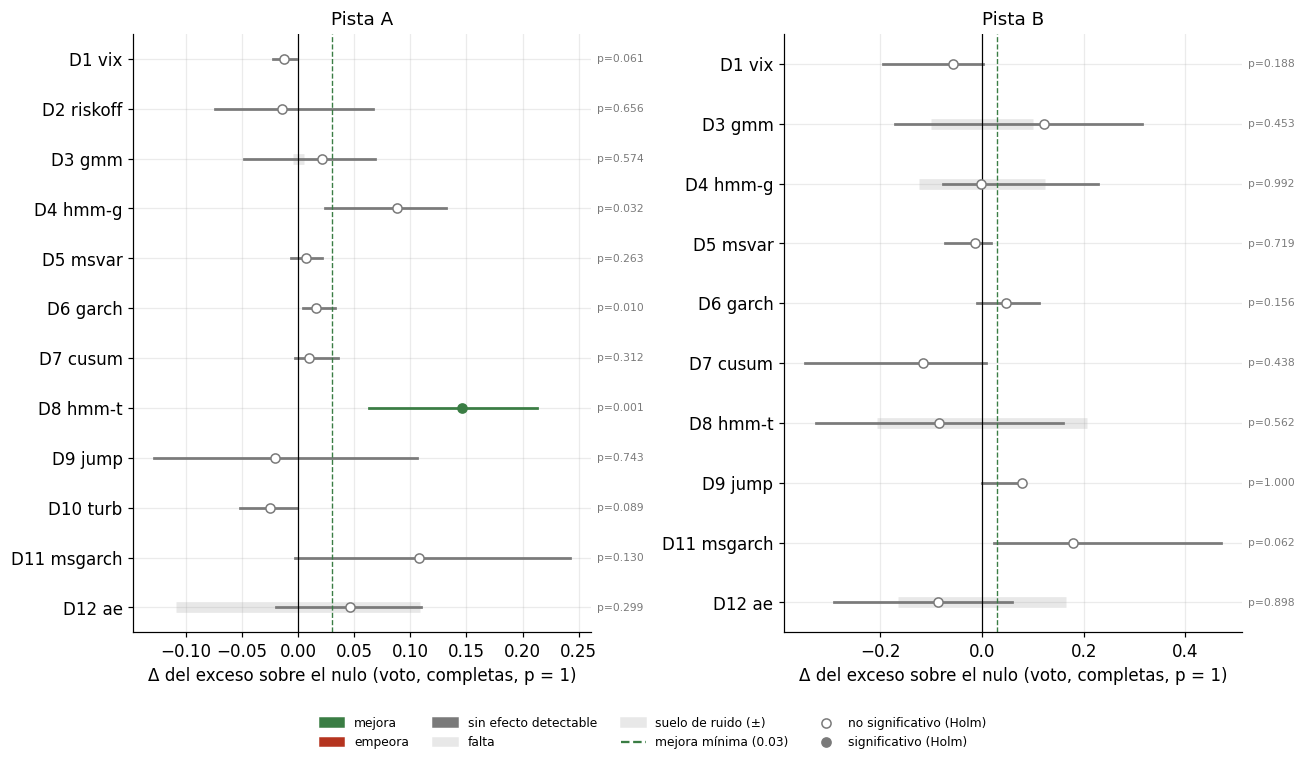

In [3]:
T1 = an.h1(DATOS, CFG)
guardar(T1, 'h1')
display(T1.reindex(columns=['pista', 'detector', 'veredicto', 'delta', 'ic_inf', 'ic_sup', 'p', 'holm', 'holm_global', 'veredicto_global', 'a_holm',
                            'b_minima', 'c_nivel', 'd_generadores', 'e_suelo', 'nivel_base', 'nivel_aumento',
                            'suelo_ruido']).round(3))
guardar(fg.fig_h1(T1, CFG), 'h1_forest')

## 4. Mapa detector × generador (exploratorio)

Δ de cada generador por separado, del voto y del control (brazo completas, p = 1). Sirve para ver si el
voto resume a los cinco o lo arrastra uno; no se elige ningún generador a posteriori.

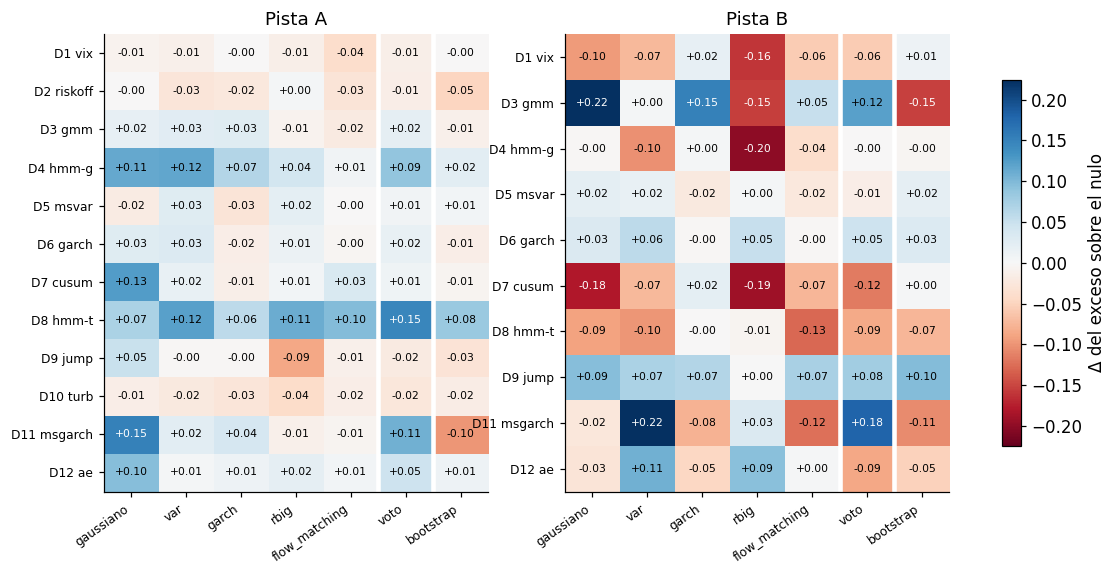

In [4]:
guardar(fg.fig_mapa(an.mapa_deltas(DATOS, cfg=CFG), CFG), 'mapa_detector_generador')

## 5. H2: dosis-respuesta

Δ(voto) frente a la proporción p ∈ {0; 0,25; 0,5; 1} en los dos brazos: líneas finas por detector y
gruesas para la media de cada grupo de H4, con IC bootstrap. La tabla da la pendiente MCO por detector
(Δ₀ = 0) con su IC; si H1 se cumple en un detector, se espera pendiente > 0. Secundaria, sin corrección.

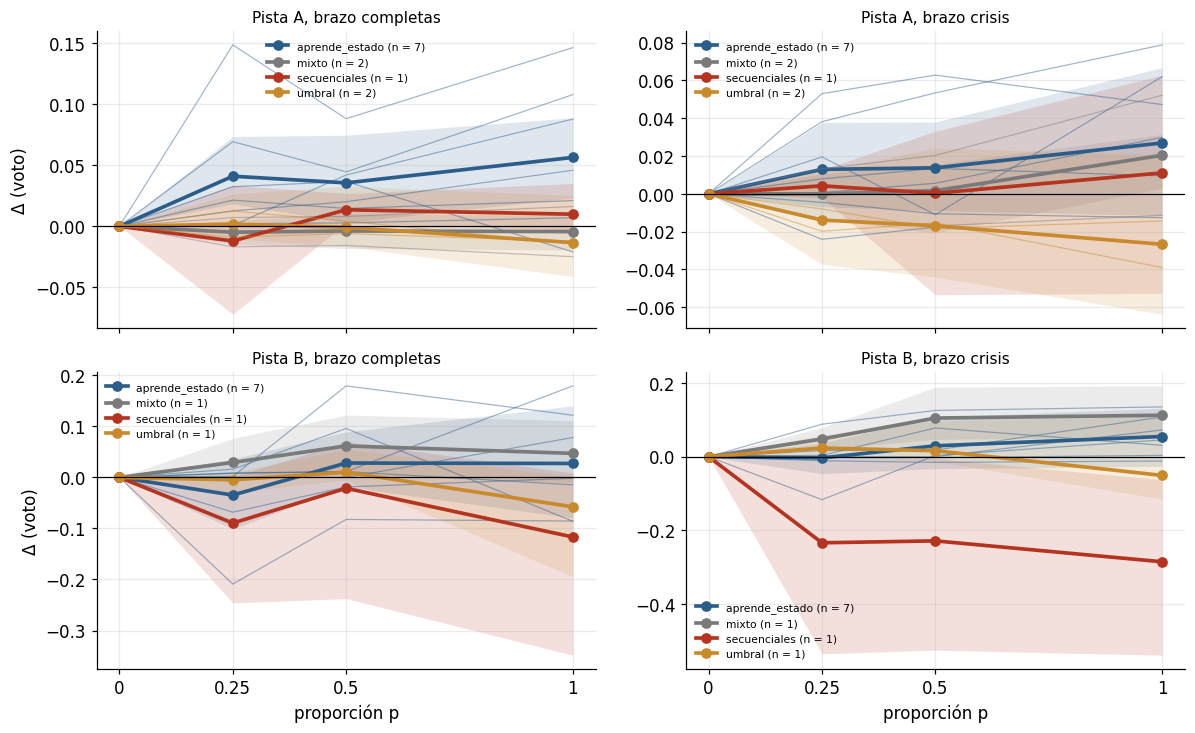

brazo                         completas                   crisis
pista detector                                                  
A     D01       -0.010 [-0.021, +0.000]  -0.014 [-0.054, +0.036]
      D02       -0.018 [-0.078, +0.059]  -0.035 [-0.102, +0.035]
      D03       +0.016 [-0.052, +0.062]  -0.021 [-0.052, +0.004]
      D04       +0.095 [+0.031, +0.145]  +0.031 [-0.004, +0.064]
      D05       +0.007 [-0.007, +0.021]  -0.013 [-0.023, -0.001]
      D06       +0.015 [+0.004, +0.031]  +0.051 [+0.005, +0.082]
      D07       +0.016 [-0.005, +0.043]  +0.010 [-0.061, +0.065]
      D08       +0.110 [+0.036, +0.165]  +0.074 [-0.012, +0.148]
      D09       -0.028 [-0.130, +0.087]  +0.038 [-0.046, +0.133]
      D10       -0.022 [-0.047, +0.000]  -0.009 [-0.036, +0.025]
      D11       +0.092 [-0.011, +0.204]  +0.056 [-0.092, +0.169]
      D12       +0.045 [-0.021, +0.111]  +0.009 [-0.025, +0.041]
B     D01       -0.057 [-0.193, +0.007]  -0.058 [-0.125, +0.106]
      D03       +0.145 [-0.154, +0.350]  +0.123 [-0.232, +0.504]
      D04       +0.019 [-0.052, +0.214]  -0.010 [-0.067, +0.181]
      D05       -0.017 [-0.078, +0.015]  +0.005 [-0.013, +0.013]
      D06       +0.045 [-0.013, +0.109]  +0.111 [+0.052, +0.196]
      D07       -0.092 [-0.346, +0.058]  -0.239 [-0.440, -0.058]
      D08       -0.026 [-0.241, +0.223]  +0.087 [-0.184, +0.237]
      D09       +0.080 [+0.000, +0.087]  +0.075 [-0.032, +0.076]
      D11       +0.183 [+0.018, +0.460]  +0.039 [-0.069, +0.234]
      D12       -0.083 [-0.300, +0.070]  +0.107 [-0.011, +0.398]

In [5]:
T2 = an.h2(DATOS, CFG)
guardar(T2, 'h2')
guardar(fg.fig_dosis(an.dosis_respuesta(DATOS, CFG), CFG), 'h2_dosis')
display(an.con_ic(T2, 'pendiente', columnas='brazo'))

## 6. H3 (control), H4 (familias) y H5 (brazos)

- **H3:** Δ(voto) − Δ(`bootstrap_regimen`), completas, p = 1. Como el voto promedia cinco ajustes y el
  control es uno, se publica también la media de los cinco Δ(generador) − Δ(control).
- **H4:** Δ medio del grupo que aprende un estado latente menos el del grupo de umbral puro (en B el grupo
  umbral queda solo en D01). Predicción: > 0. Va en la cabecera de cada fila de la figura y en la tabla.
- **H5:** Δ(crisis) − Δ(completas) con p = 1: con la misma p, «completas» añade en esperanza los mismos
  días de crisis más la calma, así que estima, con el signo cambiado, el efecto de añadir calma. Sin
  predicción de signo.

Secundarias, sin corrección: IC 95 % bootstrap pareado (azul/rojo si excluye el 0).

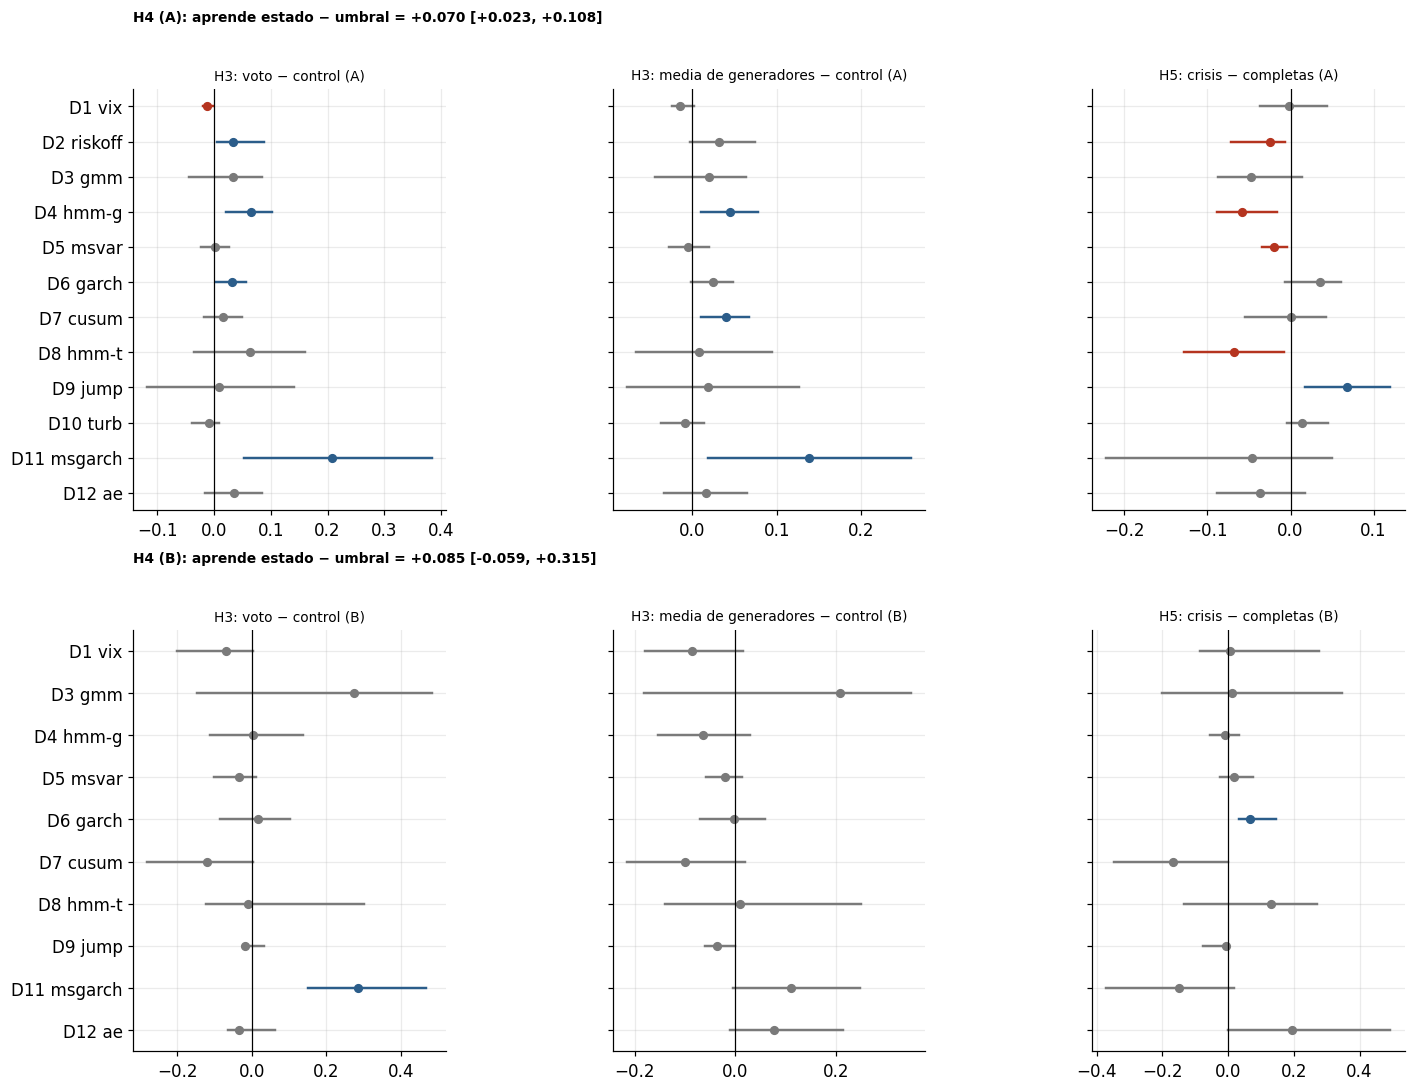

,pista,aprende_estado,umbral,diferencia,ic_inf,ic_sup
0,A,"D03,D04,D05,D08,D09,D11,D12","D01,D02",0.070,0.023,0.108
1,B,"D03,D04,D05,D08,D09,D11,D12",D01,0.085,-0.059,0.315


In [6]:
T3, T4, T5 = an.h3(DATOS, CFG), an.h4(DATOS, CFG), an.h5(DATOS, CFG)
for t, nombre in ((T3, 'h3'), (T4, 'h4'), (T5, 'h5')):
    guardar(t, nombre)
guardar(fg.fig_contrastes(T3, T5, T4, CFG), 'h3_h4_h5')
display(T4.round(3))

## 7. Diagnósticos (exploratorios)

**Recalibración frente a aprendizaje y ocupación de estados** (primera figura). (a) Si el recall solo sube
cuando se marcan más días, el aumento recalibra (marcar siempre ya da un score crudo alto). (b) Puntos por
debajo de la diagonal: parte de la ganancia en score crudo se explica por marcar más y el exceso la
descuenta. (c) Pliegues en que un estado aparece en el bloque sintético y nunca en el train real: queda al
final del orden económico, es decir, como crisis (no se excluye; cuenta en la Δ).

**Robustez** (segunda figura). (a) Sensibilidad declarada a la fuga de diseño: Δ de H1 solo en las crisis que empiezan
después de `fin_train` del 17 + margen (la familia y los parámetros de los generadores se eligieron con
datos posteriores a los primeros pliegues). (b) Réplica de B: muestras nuevas de cada generador
(repetición 1) frente a la repetición 0. (c) Suelo de ruido: el mayor |Δ| entre semillas de los detectores
estocásticos con p = 0, frente al |Δ| de H1.

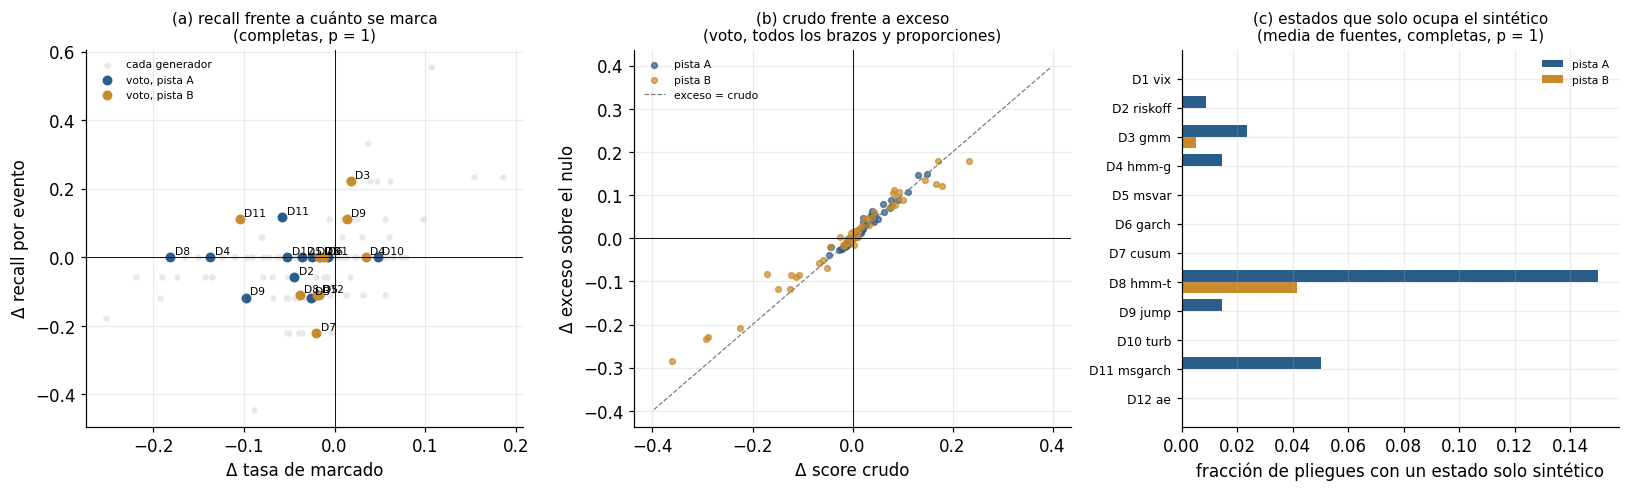

In [7]:
guardar(fg.fig_diagnosticos(an.deltas_metricas(DATOS), an.ocupacion(FILAS), CFG), 'diagnosticos')

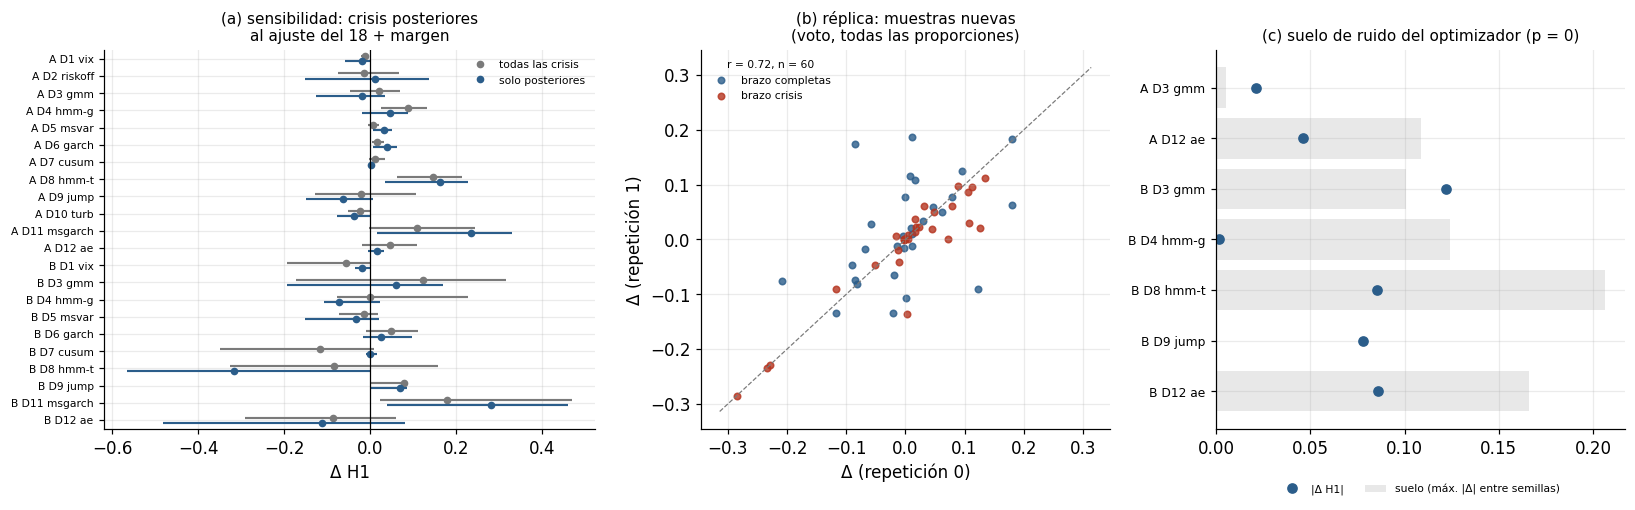

In [8]:
POST, SUELO, REP = an.h1_posterior(DATOS, CFG), an.suelo_ruido(DATOS, CFG), an.replica(DATOS, CFG)
guardar(fg.fig_robustez(T1, POST, SUELO, REP), 'robustez')

## 8. Regla para el 21 y conclusiones

Regla fijada en el pre-registro: el aumento (voto, completas, p = 1) se adopta para un detector y pista
**solo** si H1 da «mejora» y H3 tiene IC > 0 en esa pista; si no, se descarta.

In [9]:
R19 = an.regla_19(T1, T3)
guardar(R19, 'regla_19')
display(R19.round(3))

,pista,detector,veredicto,h3_ic_inf,adoptar
0,A,D01,sin efecto detectable,-0.020,False
1,A,D02,sin efecto detectable,0.005,False
2,A,D03,sin efecto detectable,-0.044,False
3,A,D04,sin efecto detectable,0.020,False
4,A,D05,sin efecto detectable,-0.023,False
5,A,D06,sin efecto detectable,0.003,False
6,A,D07,sin efecto detectable,-0.019,False
7,A,D08,mejora,-0.036,False
8,A,D09,sin efecto detectable,-0.118,False
9,A,D10,sin efecto detectable,-0.040,False


### Conclusiones

Las cifras de esta sección se copian de las salidas de arriba: las tablas `h1`–`h5` y `regla_19` (guardadas en
`results/sinteticos/aumento/`), el registro de anclas (§2) y las funciones que dibujan el mapa (§4) y la
robustez (§7: `an.mapa_deltas`, `an.h1_posterior`, `an.replica`). Es la única parte del notebook con cifras
de resultados escritas a mano.

**Veredicto: el aumento con sintéticos no se adopta en ningún detector ni pista.** Es lo que se esperaba al
pre-registrar (efecto pequeño o nulo), ahora medido con el alcance amplio: 12 detectores en A, 10 en B,
5 generadores más el control, dos brazos y tres proporciones (1.166 trabajos).

1. **H1 (principal).** De los 22 contrastes, solo **D08 (HMM-t) en la pista A** da «mejora»:
   Δ = +0,146, IC 95 % [+0,063; +0,213], p = 0,001, y aguanta también el Holm global. Los otros 21 salen
   «sin efecto detectable» y ninguno «empeora» según el criterio pre-registrado (Holm con Δ < 0).
   - **Matiz de la parte negativa:** en A, D01 (−0,012) y D10 (−0,025) tienen el IC bootstrap entero por
     debajo de 0, aunque su p de permutación no es significativo (0,061 y 0,089).
   - **Nivel ADR-003:** empeora en D12 de A y en D08 de B.
2. **La mejora de D08 no se distingue de la de «más datos».** D08 en A también sube con el control
   `bootstrap_regimen` (días reales remuestreados, +0,084) y con cada uno de los cinco generadores por
   separado (de +0,059 a +0,122). H3 (voto − control) da +0,062 con IC [−0,036; +0,161], que incluye el 0,
   y la media de los cinco generadores menos el control es +0,008. Por eso la regla pre-registrada (H1
   «mejora» **y** H3 con IC > 0) no lo adopta.
3. **`get_regimen` no cambia.** Los detectores de producción apenas se mueven:
   - **D06 en A:** Δ = +0,016, IC [+0,005; +0,033]. Queda por debajo de la mejora mínima de 0,03, no pasa
     Holm y dos generadores lo empeoran.
   - **D05 en B:** Δ = −0,015.
4. **Secundarias (sin corrección, se leen como apoyo).**
   - **H4 se cumple en A:** los detectores que aprenden un estado latente ganan más que los de umbral
     (+0,070, IC [+0,023; +0,108]). En B no es concluyente, porque el grupo umbral queda solo en D01.
   - **H2:** en el brazo completas, la pendiente es > 0 en D04, D06 y D08 de A y en D11 de B (más
     sintético, más Δ). En A encaja con el punto 2: a los HMM de A les vienen bien más datos.
   - **D04 en A** es el candidato más cercano a pasar: Δ = +0,088 [+0,024; +0,131], p = 0,032, y H3 con
     IC > 0 (+0,064 [+0,020; +0,102]). Solo le falla el Holm.
   - **D11 (MS-GARCH)** es el único que supera al control en las dos pistas (H3 con IC > 0), pero no pasa
     H1. Además, buena parte de esa ventaja viene de que el control lo empeora (−0,10 en A y en B). Queda
     como indicio exploratorio; es estable en la réplica de B y positivo en las crisis posteriores.
   - **H5, sin predicción de signo:** en A, añadir solo crisis rinde menos que añadir trayectorias
     completas en 4 de 12 detectores (D02, D04, D05 y D08 con IC < 0). Es un indicio de que la calma
     también aporta, aunque D09 en A y D06 en B salen al revés.
5. **Robustez.**
   - D08 en A mantiene la mejora en las crisis posteriores a la elección de los generadores
     (+0,162, IC [+0,033; +0,227]).
   - En B la réplica con muestras nuevas mueve mucho la Δ (completas, p = 1): D12 pasa de −0,086 a
     +0,173, D03 de +0,122 a −0,089 y D01 de −0,058 a +0,028. La semilla del muestreo pesa tanto como el
     efecto.
   - Con 9 crisis en B, el p mínimo alcanzable es 0,0039, así que la potencia en B es baja.
6. **Límites declarados.**
   - En B, D02 y D10 quedan fuera porque los generadores no producen sus columnas.
   - `difusion`, `cvae` y `cgan` no entran.
   - Algunas anclas no pasan el condicionamiento (`flow_matching` pierde 8 de 63 en A y 5 de 18 en B;
     `garch_regimen` 4 y `var_regimen` 1 en A), y las primeras se descartan por pocas crisis.
   - La incertidumbre del ajuste de cada generador por ancla no se recoge.

**Para el TFM:** los sintéticos se quedan como herramienta de laboratorio (notebook 19) y de validación
(notebook 18), no como aumento de entrenamiento. Es un resultado nulo bien diseñado.

Como pistas para el futuro, ninguna adoptada:
- En A, los HMM (D04, D08) mejoran con más datos, reales remuestreados o sintéticos, sin que el sintético
  aporte más que el remuestreo.
- D11 es el caso contrario: el remuestreo lo empeora y solo mejora con sintético.

Siguiente: [`21_decision_final`](21_decision_final.ipynb).
